In [1]:
import mdtraj as md
import numpy as np
import matplotlib.pyplot as plt


nucls = ["AUUC", "AAUC", "ACUC", "AGUC", "AUAC", "AUCC", "AUGC", "AUUA", "AUUG", "AUUU", "CUUC", "GUUC", "UUUC"]
base_dirs = {nucl: f"../20251002_FUS-RRM_mut/20251002_FUS-RRM_mut-{nucl}" for nucl in nucls}
base_dirs["AUUC"] = "../20250801_FUS-RRM"

gleap_targets = {nucl: md.load(f"{base_dirs[nucl]}/2_md-preparation-2/gleap.target.gro") for nucl in nucls}
atom_indices_protein             = {nucl: gleap_targets[nucl].topology.select("resid 23 to 126") for nucl in nucls}
atom_indices_rna                 = {nucl: gleap_targets[nucl].topology.select("resid  0 to  22") for nucl in nucls}
atom_index_protein_min           = {nucl: min(atom_indices_protein[nucl])                        for nucl in nucls}


def calculate_interactions(xtc, atom_indices_protein, atom_indices_rna, atom_index_protein_min, gleap_target):
    from scipy.spatial import cKDTree

    def get_atom_indices_h_bonded_no(atom_indices):
        atom_indices_h = []
        for atom_index in atom_indices:
            if gleap_target.topology.atom(atom_index).name[0] == "H":
                for atom1, atom2 in gleap_target.topology.bonds:
                    if atom1.index == atom_index:
                        if gleap_target.topology.atom(atom2.index).name[0] in "NO":
                            atom_indices_h.append(atom_index)
                    if atom2.index == atom_index:
                        if gleap_target.topology.atom(atom1.index).name[0] in "NO":
                            atom_indices_h.append(atom_index)
        return atom_indices_h

    def compute_hbond_pairs(xyz_1, xyz_2):
        hbond_pairs = []
        tree = cKDTree(xyz_2)
        neighbors = tree.query_ball_point(xyz_1, r=0.25)
        for i_1, is_2 in enumerate(neighbors):
            for i_2 in is_2:
                hbond_pairs.append((i_1, i_2))
        return hbond_pairs

    _interactions = np.zeros((len(atom_indices_protein), len(atom_indices_rna), xtc.n_frames))

    atom_indices_protein_h  = get_atom_indices_h_bonded_no(atom_indices_protein)
    atom_indices_protein_no = [index for index in atom_indices_protein if gleap_target.topology.atom(index).name[0] in "NO"]
    atom_indices_rna_h      = get_atom_indices_h_bonded_no(atom_indices_rna)
    atom_indices_rna_no     = [index for index in atom_indices_rna     if gleap_target.topology.atom(index).name[0] in "NO"]

    for timestep in range(xtc.n_frames):
        xyz_protein_h  = xtc.xyz[timestep, atom_indices_protein_h]
        xyz_protein_no = xtc.xyz[timestep, atom_indices_protein_no]
        xyz_rna_h      = xtc.xyz[timestep, atom_indices_rna_h]
        xyz_rna_no     = xtc.xyz[timestep, atom_indices_rna_no]

        for i_protein, i_rna in compute_hbond_pairs(xyz_protein_no, xyz_rna_h):
            atom_index_protein = atom_indices_protein_no[i_protein]
            atom_index_rna     = atom_indices_rna_h[i_rna]
            _interactions[atom_index_protein-atom_index_protein_min, atom_index_rna, timestep] += 1

        for i_protein, i_rna in compute_hbond_pairs(xyz_protein_h, xyz_rna_no):
            atom_index_protein = atom_indices_protein_h[i_protein]
            atom_index_rna     = atom_indices_rna_no[i_rna]
            _interactions[atom_index_protein-atom_index_protein_min, atom_index_rna, timestep] += 1

    nonzero_indices = _interactions.nonzero()
    return nonzero_indices, _interactions[nonzero_indices]


interactions_mut = {}
for i_nucl, nucl in enumerate(nucls):
    print(nucl)
    interactions_mut[nucl] = np.zeros((5, len(atom_indices_protein[nucl]), len(atom_indices_rna[nucl]), 1500))
    for trial in range(len(interactions_mut[nucl])):
        xtc = md.load(f"{base_dirs[nucl]}/6_cmd-{trial+1}/cmd.skip10.whole.target.pbc.xtc", top=gleap_targets[nucl])[5001::10]
        nonzero_indices, nonzero_vals = calculate_interactions(xtc, atom_indices_protein[nucl], atom_indices_rna[nucl], atom_index_protein_min[nucl], gleap_targets[nucl])
        interactions_mut[nucl][trial][nonzero_indices] = nonzero_vals

AUUC
AAUC
ACUC
AGUC
AUAC
AUCC
AUGC
AUUA
AUUG
AUUU
CUUC
GUUC
UUUC


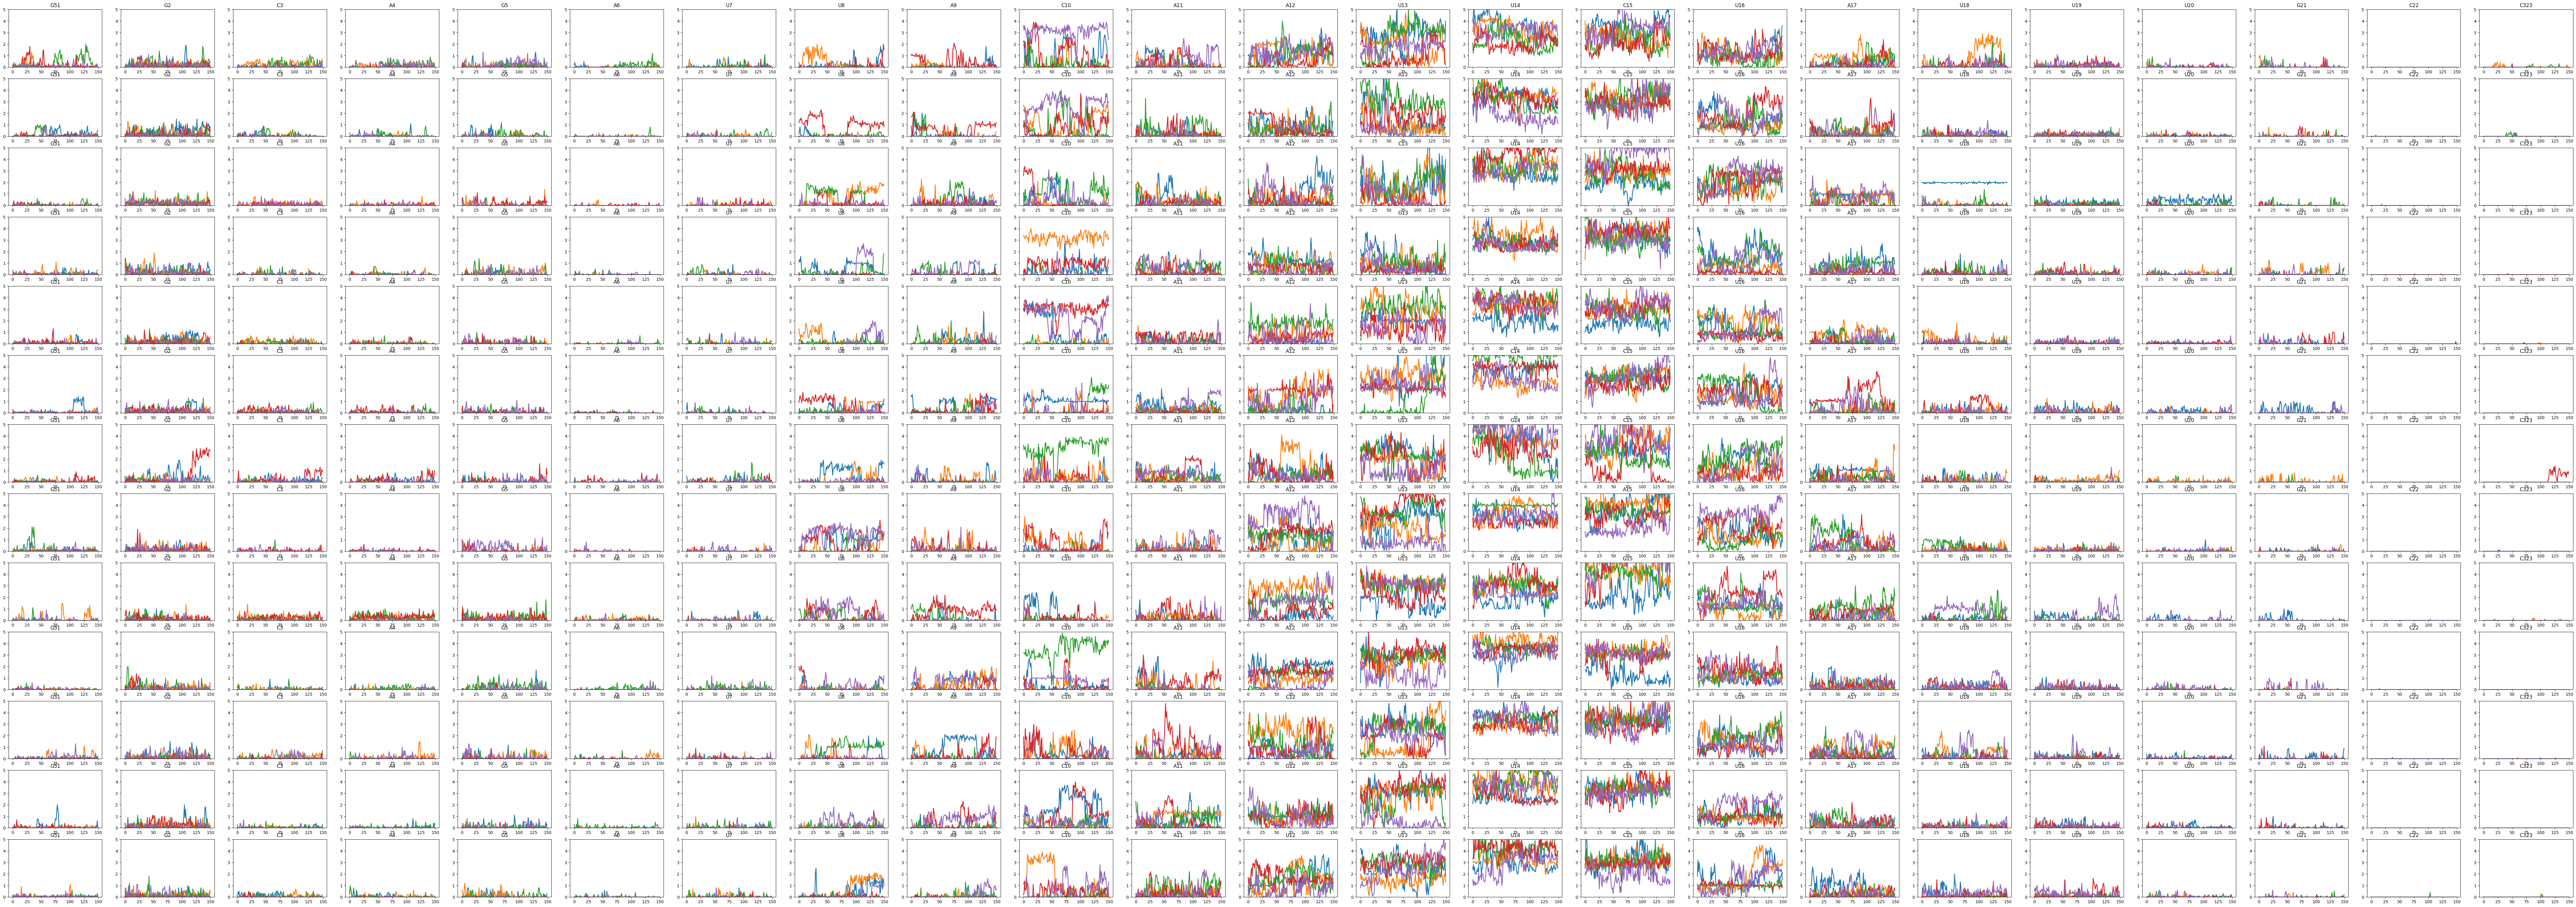

In [2]:
YMAX = 5

fig, ax = plt.subplots(len(nucls), 23)
fig.set_size_inches(112, 3*len(nucls))

for i_nucl, nucl in enumerate(nucls):
    for trial in range(len(interactions_mut[nucl])):
        for residue_index_rna in range(0, 23):
            atom_idices_rna_residue = gleap_targets[nucl].topology.select(f"resid {residue_index_rna}")
            atom_index_rna_resiude_min = min(atom_idices_rna_residue)
            atom_index_rna_resiude_max = max(atom_idices_rna_residue)
            
            interactions_sum = interactions_mut[nucl][trial, :, atom_index_rna_resiude_min:atom_index_rna_resiude_max+1, :].sum(axis=0).sum(axis=0).reshape(-1, 10).mean(axis=1)
    
            ax[i_nucl, residue_index_rna].plot(interactions_sum, linewidth=2)
            ax[i_nucl, residue_index_rna].set_title(gleap_targets[nucl].topology.residue(residue_index_rna))
            ax[i_nucl, residue_index_rna].set_ylim(0, YMAX)

In [3]:
def make_label_protein(atom):
    return f"{atom.residue.name}{atom.residue.index+252}-{atom.name}"


fractions = {nucl: interactions_mut[nucl].mean(axis=0).mean(axis=2) for nucl in nucls}

for nucl in nucls:
    print(nucl)
    for index_row, index_column in zip(*np.unravel_index(np.argsort(fractions[nucl], axis=None)[-30:][::-1], fractions[nucl].shape)):
        print(f"{make_label_protein(gleap_targets[nucl].topology.atom(index_row+atom_index_protein_min[nucl]))}={gleap_targets[nucl].topology.atom(index_column)}: {fractions[nucl][index_row, index_column]:.2f}")

AUUC
THR370-H=U14-O2: 0.99
THR370-O=U14-HO2': 0.71
ARG372-H=C15-OP2: 0.64
THR370-HG1=U14-O2': 0.51
ALA369-O=C15-H42: 0.38
ASN323-HD21=U16-OP2: 0.33
THR326-H=U13-O2: 0.29
THR326-OG1=U13-H3: 0.28
THR286-HG1=C15-O2: 0.28
ALA373-H=C15-OP2: 0.23
ARG377-HE=C10-O2: 0.22
ASN323-HD22=U16-OP2: 0.21
ARG372-HH21=C15-OP1: 0.19
ARG377-HH11=C10-N3: 0.19
ARG372-HE=C15-OP1: 0.18
LEU324-O=A12-H61: 0.17
THR326-H=U13-OP1: 0.14
ARG377-HH11=C10-O2: 0.13
NME378-H=C10-O2': 0.12
THR326-O=U13-H3: 0.11
ARG372-HH11=U14-OP1: 0.11
ARG371-HH11=A17-OP1: 0.11
ARG328-HH22=U13-OP2: 0.10
ARG371-HH12=C15-O2': 0.10
LYS334-HZ3=U14-OP2: 0.09
ASN284-OD1=C15-H41: 0.09
ASN323-HD21=U16-OP1: 0.08
ARG372-HE=C15-OP2: 0.08
ARG328-H=U13-O4: 0.08
ARG328-H=U13-O2: 0.08
AAUC
THR370-H=U14-O2: 0.87
THR370-O=U14-HO2': 0.82
ARG372-H=C15-OP2: 0.73
THR370-HG1=U14-O2': 0.41
ALA369-O=C15-H42: 0.38
ALA373-H=C15-OP2: 0.31
THR286-HG1=C15-O2: 0.28
ASN323-HD21=U16-OP2: 0.26
ASN323-HD22=U16-OP2: 0.23
THR326-H=A13-N7: 0.20
ARG377-HE=C10-O2: 0.16
ARG37

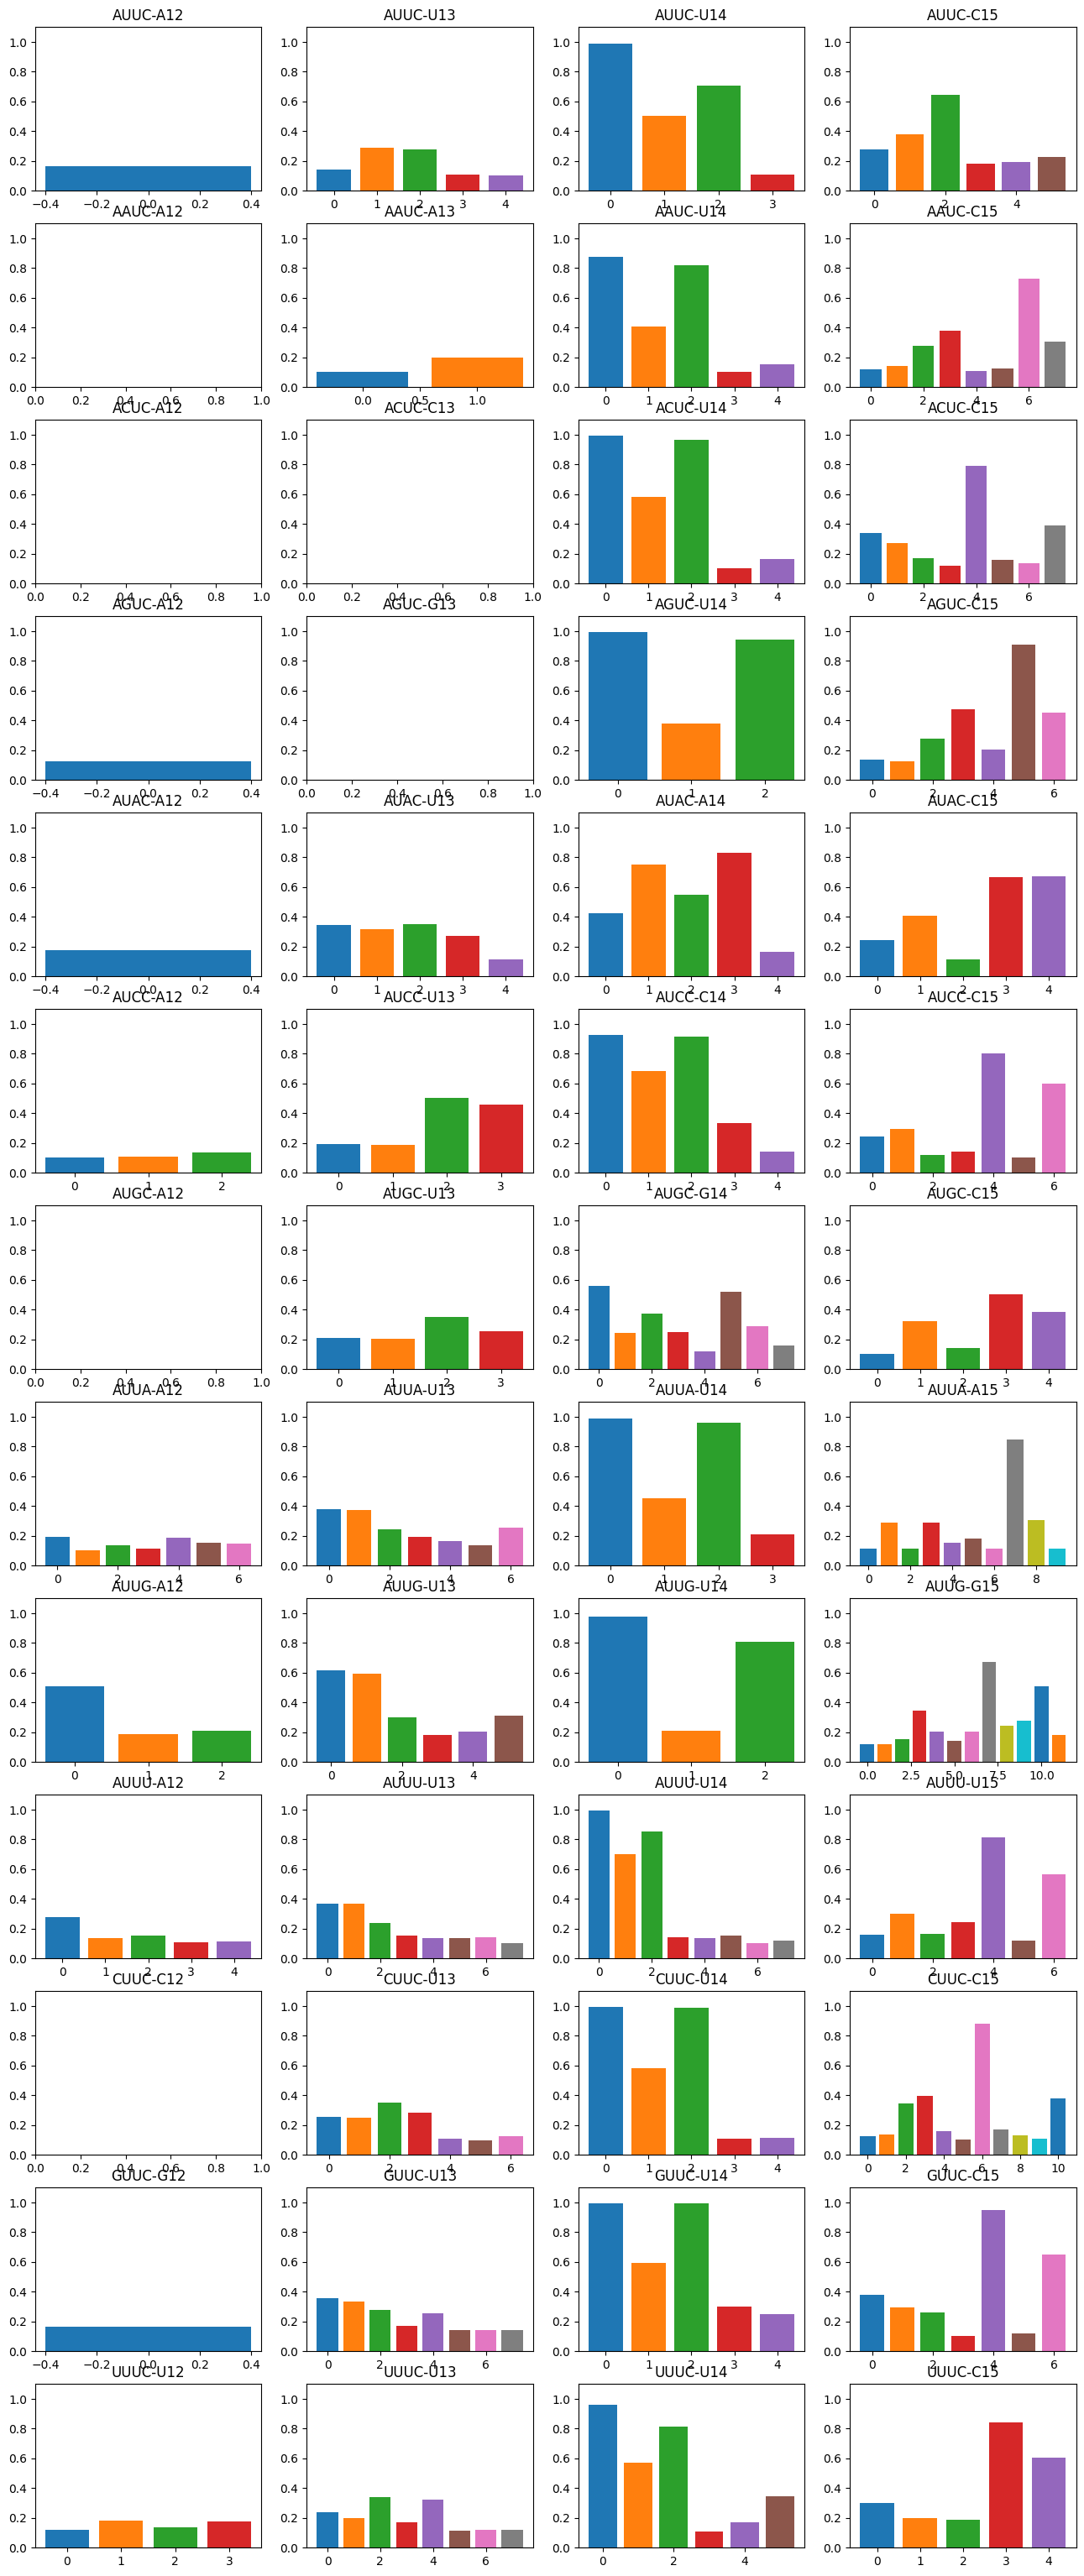

In [4]:
fig, ax = plt.subplots(len(interactions_mut), 4)
fig.set_size_inches(16, 3*len(interactions_mut))

for i_nucl, nucl in enumerate(nucls):
    for residue_index_rna in range(11, 15):
        atom_indices_rna_residue = gleap_targets[nucl].topology.select(f"resid {residue_index_rna}")
    
        dominant_pairs = []
        for atom_index_protein, atom_index_rna in np.argwhere(fractions[nucl] > 0.1):
            if atom_index_rna in atom_indices_rna_residue:
                dominant_pairs.append((atom_index_protein, atom_index_rna))
    
        xticks = []
        offset = 0
        for atom_index_protein, atom_index_rna in dominant_pairs:
            ax[i_nucl, residue_index_rna-11].bar(offset, fractions[nucl][atom_index_protein, atom_index_rna])
            xticks.append(f"{make_label_protein(gleap_targets[nucl].topology.atom(atom_index_protein+atom_index_protein_min[nucl]))}={gleap_targets[nucl].topology.atom(atom_index_rna)}")
            offset += 1
        ax[i_nucl, residue_index_rna-11].set_title(f"{nucl}-{gleap_targets[nucl].topology.residue(residue_index_rna)}")
        ax[i_nucl, residue_index_rna-11].set_ylim(0, 1.1)
        # ax[i_nucl, residue_index_rna-11].set_xticks(range(len(xticks)), xticks, rotation=-45)

In [5]:
for i_nucl, nucl in enumerate(nucls):
    fraction_sum_nucl = 0
    for residue_index_rna in range(11, 15):
        fraction_sum_rna_residue = 0
        atom_indices_rna_residue = gleap_targets[nucl].topology.select(f"resid {residue_index_rna}")

        for atom_index_protein, atom_index_rna in np.argwhere(fractions[nucl] > 0):
            if atom_index_rna in atom_indices_rna_residue:
                fraction_sum_rna_residue += fractions[nucl][atom_index_protein, atom_index_rna]

        fraction_sum_nucl += fraction_sum_rna_residue
        print(nucl, gleap_targets[nucl].topology.residue(residue_index_rna), fraction_sum_rna_residue)
    print(nucl, fraction_sum_nucl)
    print()

AUUC A12 1.1058666666666654
AUUC U13 1.9670666666666654
AUUC U14 2.8377333333333334
AUUC C15 2.775999999999997
AUUC 8.68666666666666

AAUC A12 0.6453333333333331
AAUC A13 1.5265333333333309
AAUC U14 3.0355999999999983
AAUC C15 3.114799999999998
AAUC 8.32226666666666

ACUC A12 0.6083999999999999
ACUC C13 1.2403999999999997
ACUC U14 3.386133333333332
ACUC C15 3.0378666666666656
ACUC 8.272799999999998

AGUC A12 0.7210666666666662
AGUC G13 0.810133333333333
AGUC U14 2.8393333333333337
AGUC C15 3.3682666666666656
AGUC 7.738799999999998

AUAC A12 0.7813333333333328
AUAC U13 2.2401333333333318
AUAC A14 3.2142666666666666
AUAC C15 2.8142666666666654
AUAC 9.049999999999995

AUCC A12 0.9407999999999993
AUCC U13 2.329466666666664
AUCC C14 3.5963999999999987
AUCC C15 2.9631999999999987
AUCC 9.82986666666666

AUGC A12 0.7486666666666664
AUGC U13 1.8474666666666648
AUGC G14 3.3253333333333313
AUGC C15 2.779999999999998
AUGC 8.70146666666666

AUUA A12 1.4747999999999986
AUUA U13 2.5638666666666645
AU

AUUC
LEU324-O A12-H61 0.000846740050804403 0.31210513014910285
THR326-H U13-O2 0.12785774767146485 0.4303765478898155
THR326-OG1 U13-H3 0.11995484053062376 0.41799342936568107
THR370-H U14-O2 0.9822184589331076 0.994187515794794
THR370-HG1 U14-O2' 0.4504657070279424 0.5549658832448825
THR370-O U14-HO2' 0.6028789161727349 0.7970684862269396
THR286-HG1 C15-O2 0.21845893310753597 0.3260045489006823
ALA369-O C15-H42 0.4809483488569009 0.2926459438968916
ARG372-H C15-OP2 0.5145357042054756 0.7584028304270912
ARG372-HH21 C15-OP1 0.06576347727914197 0.3045236290118777

LEU324-O A12-H61 0.000846740050804403 0.31210513014910285
THR326-H U13-O2 0.12785774767146485 0.4303765478898155
THR326-OG1 U13-H3 0.11995484053062376 0.41799342936568107
THR370-H U14-O2 0.9822184589331076 0.994187515794794
THR370-HG1 U14-O2' 0.4504657070279424 0.5549658832448825
THR370-O U14-HO2' 0.6028789161727349 0.7970684862269396
THR286-HG1 C15-O2 0.21845893310753597 0.3260045489006823
ALA369-O C15-H42 0.4809483488569009 0

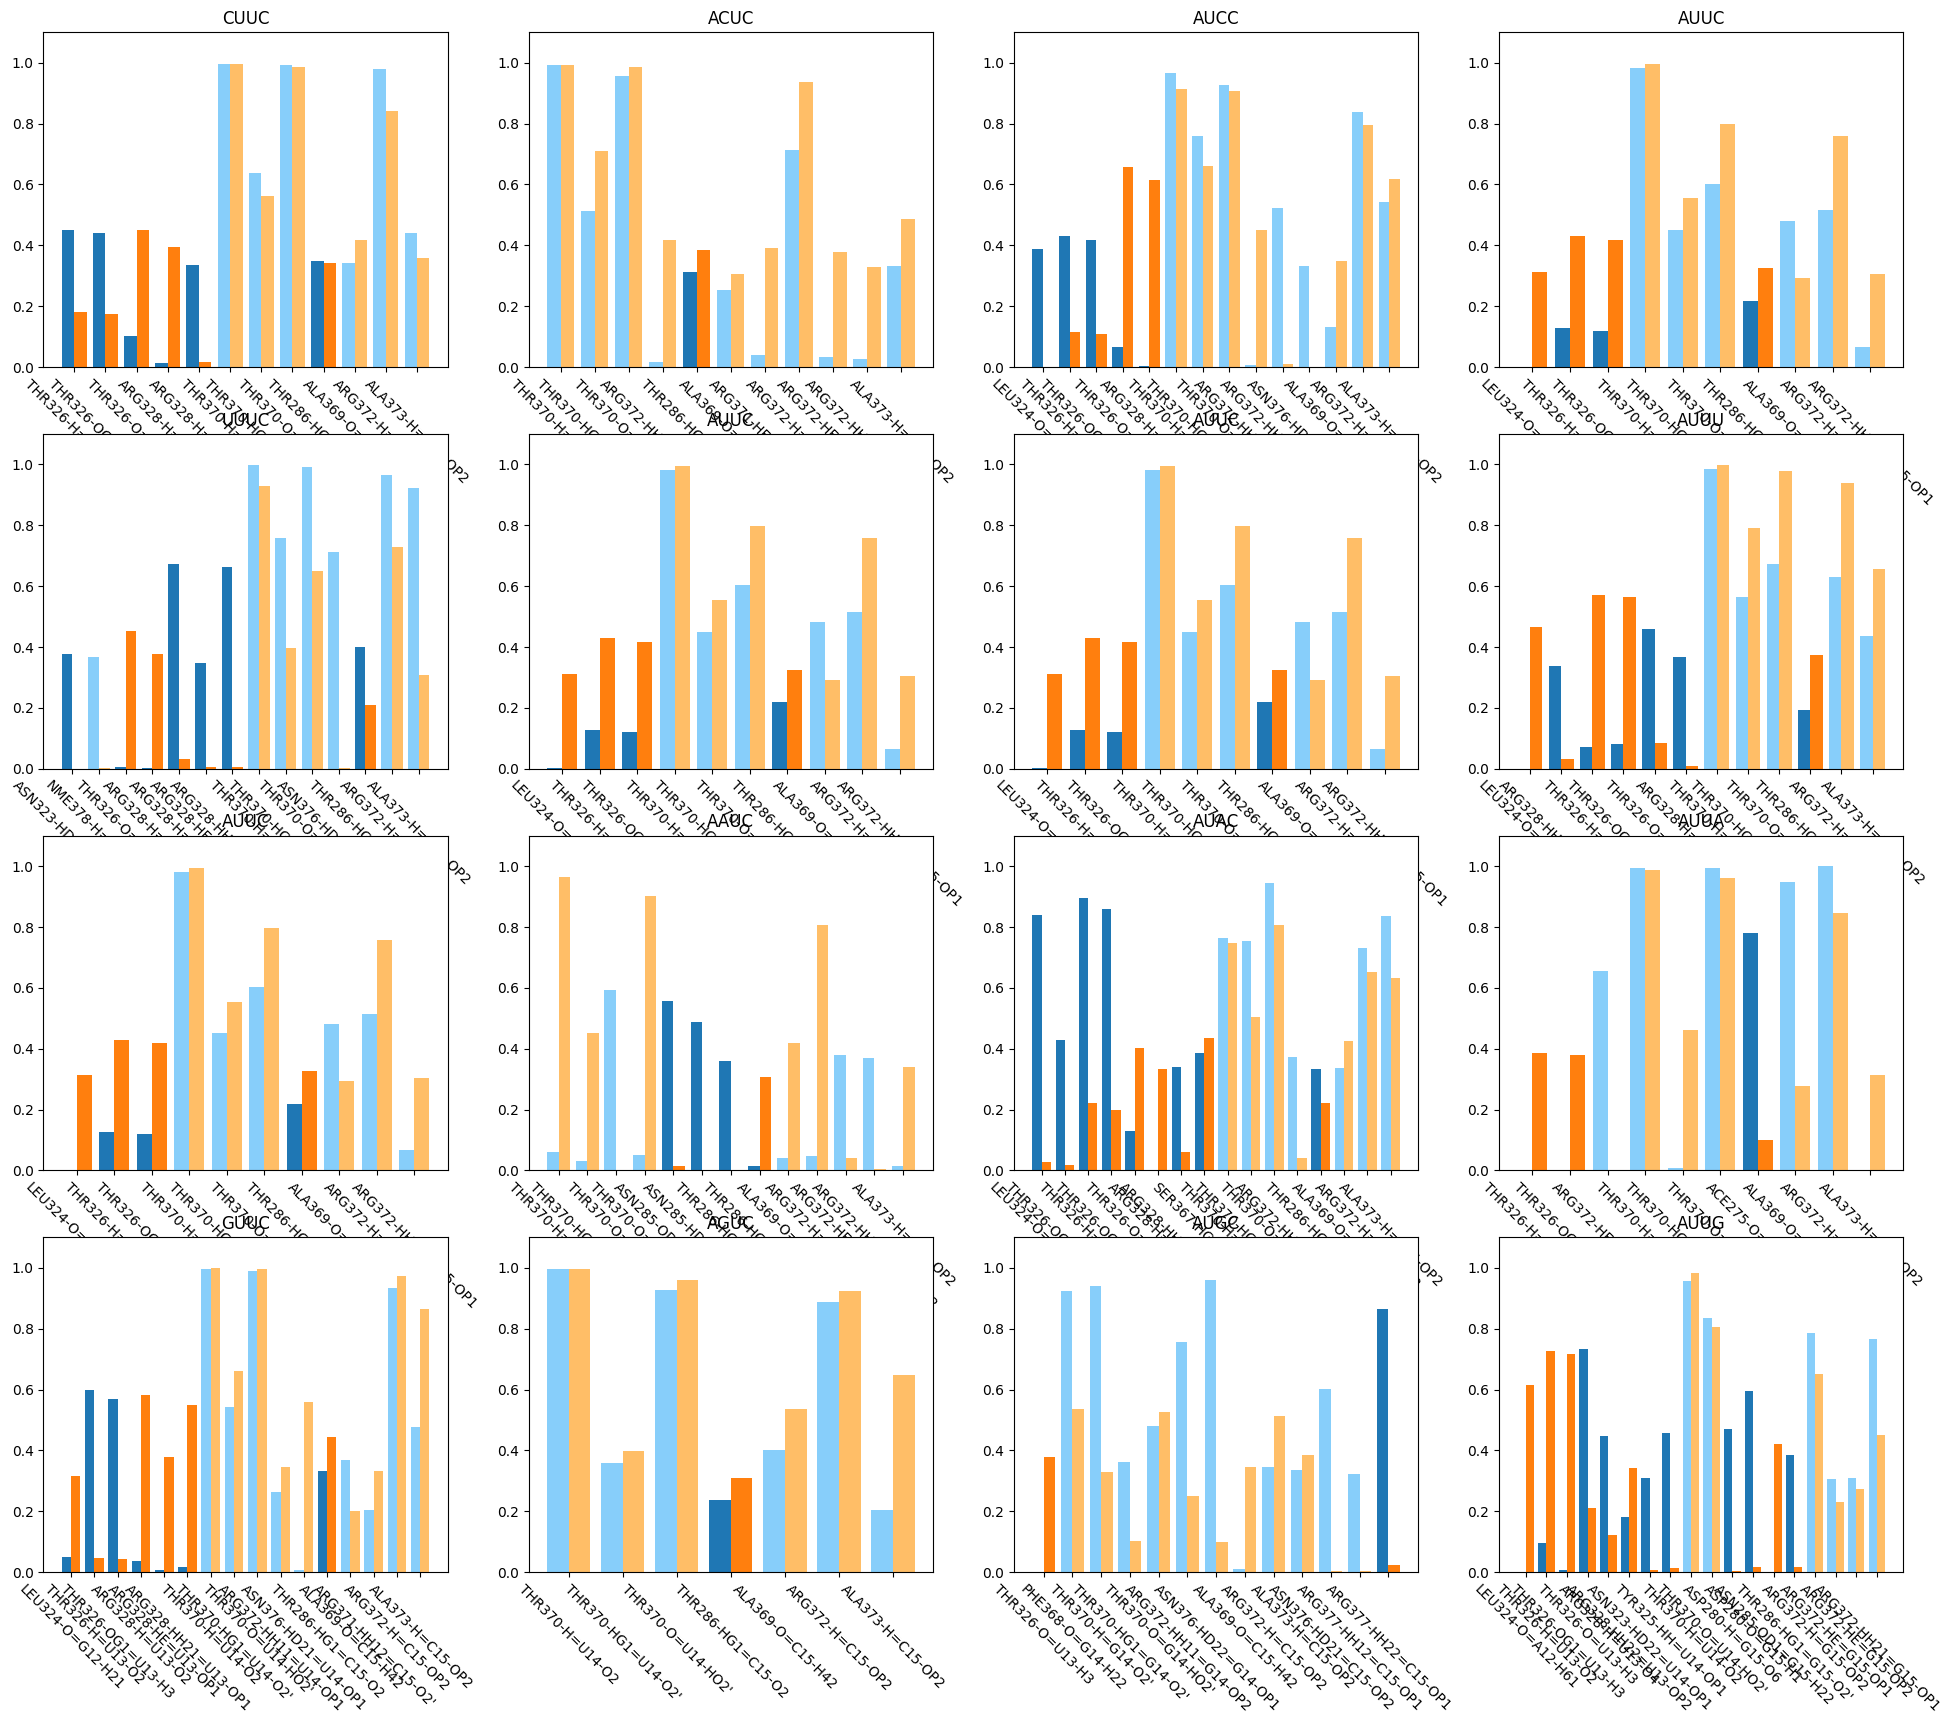

In [6]:
import pickle


atom_indices_protein_rgion = {
    "rrm": list(gleap_targets["AUUC"].topology.select("resid  24 to 116")),
    "rgg": list(gleap_targets["AUUC"].topology.select("resid 117 to 125")),
}

colors = [
    {
        "rrm": "tab:blue",
        "rgg": "lightskyblue",
    },
    {
        "rrm": "tab:orange",
        "rgg": "#FFBE67",
    },
]

ax_positions = {
    "AUUC": [(2,0), (1,1), (1,2), (0,3)],
    "AAUC": [(2,1)],
    "ACUC": [(0,1)],
    "AGUC": [(3,1)],
    "AUAC": [(2,2)],
    "AUCC": [(0,2)],
    "AUGC": [(3,2)],
    "AUUA": [(2,3)],
    "AUUG": [(3,3)],
    "AUUU": [(1,3)],
    "CUUC": [(0,0)],
    "GUUC": [(3,0)],
    "UUUC": [(1,0)],
}

fig, ax = plt.subplots(4, 4)
fig.set_size_inches(24, 20)

for i_nucl, nucl in enumerate(nucls):
    print(nucl)
    metastabled_trajs_concat = pickle.load(open(f"./pickle-cache/pca_tetranucl_mut/metastabled_trajs_concat_{nucl}.pickle", "rb")).reshape(5, 15000)[:, ::10]
    fractions0 = interactions_mut[nucl].transpose(1, 2, 0, 3)[:, :, metastabled_trajs_concat==0].mean(axis=2)
    fractions1 = interactions_mut[nucl].transpose(1, 2, 0, 3)[:, :, metastabled_trajs_concat==1].mean(axis=2)

    dominant_pairs = []
    for residue_index_rna in range(11, 15):
        atom_indices_rna_residue = gleap_targets[nucl].topology.select(f"resid {residue_index_rna}")
        for atom_index_protein, atom_index_rna in np.argwhere((fractions0 > 0.3) | (fractions1 > 0.3)):
            if atom_index_rna in atom_indices_rna_residue:
                dominant_pairs.append((atom_index_protein, atom_index_rna))

    for ax_position in ax_positions[nucl]:
        xticks = []
        offset = 0
        for atom_index_protein, atom_index_rna in dominant_pairs:
            atom_protein = gleap_targets[nucl].topology.atom(atom_index_protein)
            atom_rna     = gleap_targets[nucl].topology.atom(atom_index_rna)

            region = "rrm"
            if atom_index_protein+atom_index_protein_min[nucl] in atom_indices_protein_rgion["rgg"]:
                region = "rgg"

            ax[ax_position].bar(offset-0.2, fractions0[atom_index_protein, atom_index_rna], width=0.4, color=colors[0][region])
            ax[ax_position].bar(offset+0.2, fractions1[atom_index_protein, atom_index_rna], width=0.4, color=colors[1][region])
            xticks.append(f"{make_label_protein(gleap_targets[nucl].topology.atom(atom_index_protein+atom_index_protein_min[nucl]))}={gleap_targets[nucl].topology.atom(atom_index_rna)}")
            print(make_label_protein(gleap_targets[nucl].topology.atom(atom_index_protein+atom_index_protein_min[nucl])), gleap_targets[nucl].topology.atom(atom_index_rna), fractions0[atom_index_protein, atom_index_rna], fractions1[atom_index_protein, atom_index_rna])
            offset += 1
        ax[ax_position].set_title(nucl)
        ax[ax_position].set_ylim(0, 1.1)
        ax[ax_position].set_xticks(range(len(xticks)), xticks, rotation=-45)
        print()
    print("--------------------")
    print()

AUUC
LEU324-O A12-H61 0.000846740050804403 0.31210513014910285
THR326-OG1 A12-H62 0.0 0.12105130149102855
THR326-H U13-O2 0.12785774767146485 0.4303765478898155
THR326-OG1 U13-H3 0.11995484053062376 0.41799342936568107
THR326-O U13-H3 0.18458933107535985 0.04498357341420268
ARG328-H U13-O4 0.1622918430708439 0.008086934546373515
ARG328-H U13-O2 0.016652554332486594 0.13646702047005307
THR370-H U14-O2 0.9822184589331076 0.994187515794794
ASN284-OD1 C15-H41 0.1117696867061812 0.06696992671215567
THR286-HG1 C15-N3 0.10076206604572396 0.05787212534748547
THR286-HG1 C15-O2 0.21845893310753597 0.3260045489006823
ALA369-O C15-H42 0.4809483488569009 0.2926459438968916

LEU324-O A12-H61 0.000846740050804403 0.31210513014910285
THR326-OG1 A12-H62 0.0 0.12105130149102855
THR326-H U13-O2 0.12785774767146485 0.4303765478898155
THR326-OG1 U13-H3 0.11995484053062376 0.41799342936568107
THR326-O U13-H3 0.18458933107535985 0.04498357341420268
ARG328-H U13-O4 0.1622918430708439 0.008086934546373515
ARG3

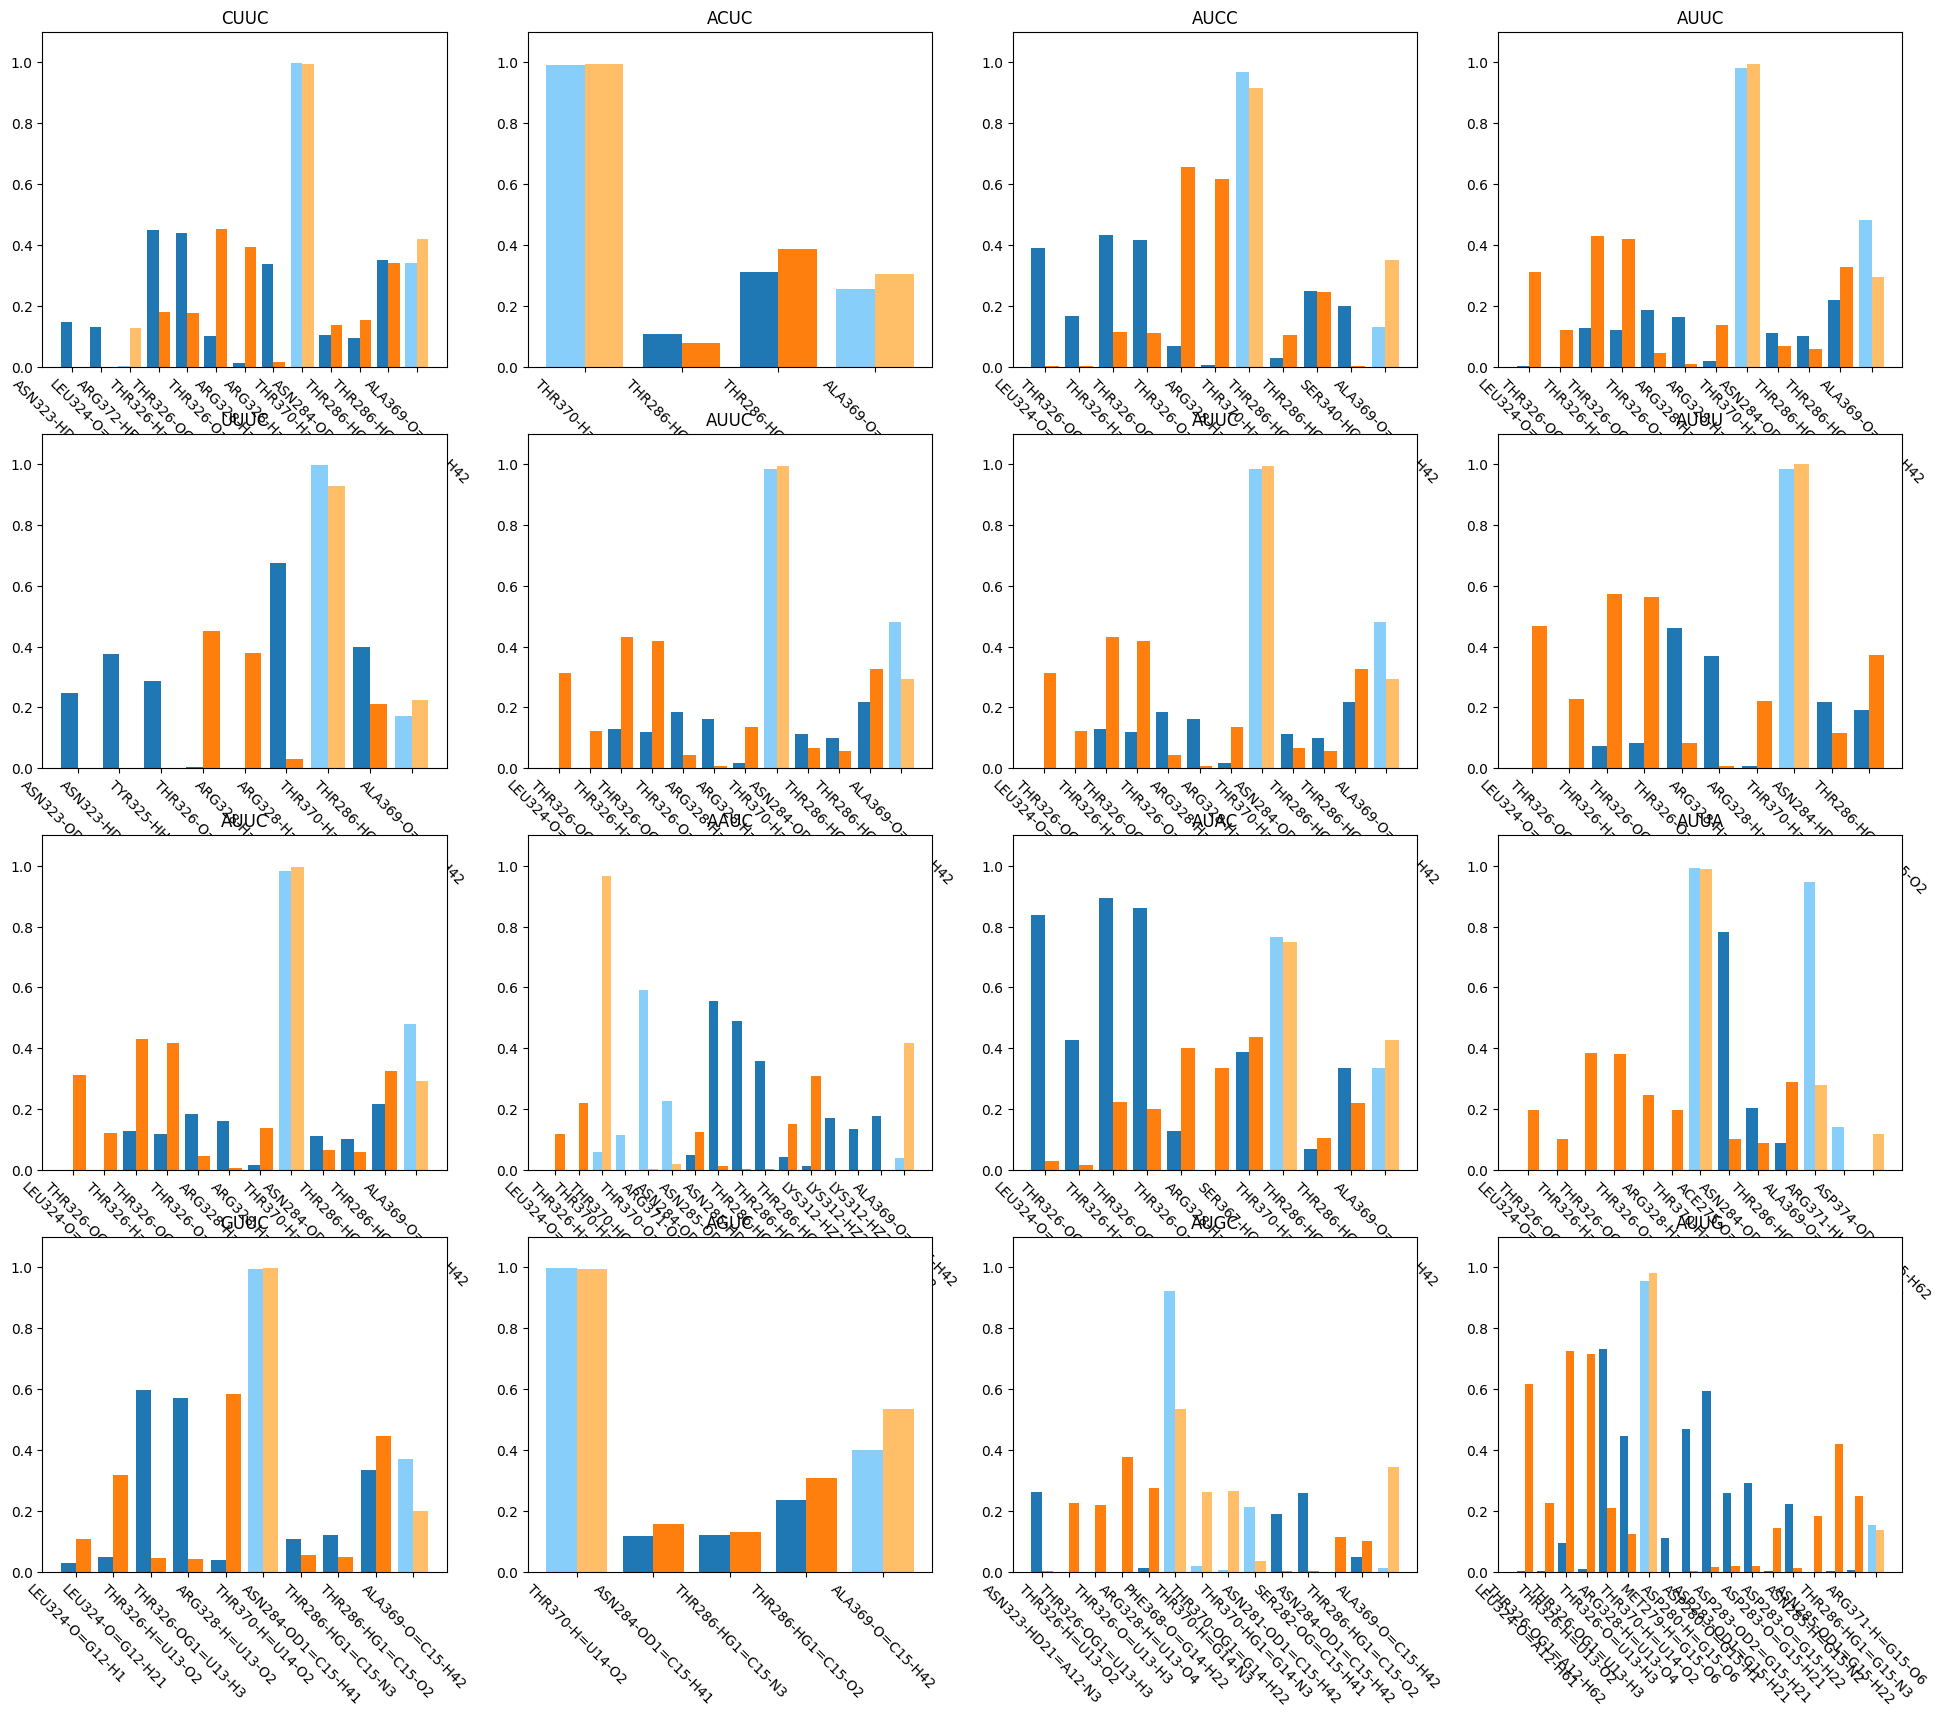

In [7]:
fig, ax = plt.subplots(4, 4)
fig.set_size_inches(24, 20)

for i_nucl, nucl in enumerate(nucls):
    print(nucl)
    metastabled_trajs_concat = pickle.load(open(f"./pickle-cache/pca_tetranucl_mut/metastabled_trajs_concat_{nucl}.pickle", "rb")).reshape(5, 15000)[:, ::10]
    fractions0 = interactions_mut[nucl].transpose(1, 2, 0, 3)[:, :, metastabled_trajs_concat==0].mean(axis=2)
    fractions1 = interactions_mut[nucl].transpose(1, 2, 0, 3)[:, :, metastabled_trajs_concat==1].mean(axis=2)

    dominant_pairs = []
    for residue_index_rna in range(11, 15):
        atom_indices_rna_residue = []
        for atom_index_rna_residue in gleap_targets[nucl].topology.select(f"resid {residue_index_rna}"):
            if "'" in gleap_targets[nucl].topology.atom(atom_index_rna_residue).name:
                continue
            if gleap_targets[nucl].topology.atom(atom_index_rna_residue).name in ["P", "OP1", "OP2"]:
                continue
            atom_indices_rna_residue.append(atom_index_rna_residue)
        
        for atom_index_protein, atom_index_rna in np.argwhere((fractions0 > 0.1) | (fractions1 > 0.1)):
            if atom_index_rna in atom_indices_rna_residue:
                dominant_pairs.append((atom_index_protein, atom_index_rna))

    for ax_position in ax_positions[nucl]:
        xticks = []
        offset = 0
        for atom_index_protein, atom_index_rna in dominant_pairs:
            atom_protein = gleap_targets[nucl].topology.atom(atom_index_protein)
            atom_rna     = gleap_targets[nucl].topology.atom(atom_index_rna)

            region = "rrm"
            if atom_index_protein+atom_index_protein_min[nucl] in atom_indices_protein_rgion["rgg"]:
                region = "rgg"

            ax[ax_position].bar(offset-0.2, fractions0[atom_index_protein, atom_index_rna], width=0.4, color=colors[0][region])
            ax[ax_position].bar(offset+0.2, fractions1[atom_index_protein, atom_index_rna], width=0.4, color=colors[1][region])
            xticks.append(f"{make_label_protein(gleap_targets[nucl].topology.atom(atom_index_protein+atom_index_protein_min[nucl]))}={gleap_targets[nucl].topology.atom(atom_index_rna)}")
            print(make_label_protein(gleap_targets[nucl].topology.atom(atom_index_protein+atom_index_protein_min[nucl])), gleap_targets[nucl].topology.atom(atom_index_rna), fractions0[atom_index_protein, atom_index_rna], fractions1[atom_index_protein, atom_index_rna])
            offset += 1
        ax[ax_position].set_title(nucl)
        ax[ax_position].set_ylim(0, 1.1)
        ax[ax_position].set_xticks(range(len(xticks)), xticks, rotation=-45)
        print()
    print("--------------------")
    print()

AUUC
A12-H61 0.02173299463731301 0.34217841799342935
A12-H62 0.000846740050804403 0.12736921910538287
U13-O4 0.1755574372001129 0.08011119535001264
U13-H3 0.3042619249223822 0.5198382613090725
U13-O2 0.1851538244425628 0.5986858731362144
U14-O2 0.9822184589331076 0.994187515794794
C15-H41 0.12898673440587072 0.09299974728329542
C15-H42 0.5574372001128987 0.3318170331058883
C15-N3 0.10753598645215919 0.06368460955269144
C15-O2 0.2548687552921253 0.36315390447308565

A12-H61 0.02173299463731301 0.34217841799342935
A12-H62 0.000846740050804403 0.12736921910538287
U13-O4 0.1755574372001129 0.08011119535001264
U13-H3 0.3042619249223822 0.5198382613090725
U13-O2 0.1851538244425628 0.5986858731362144
U14-O2 0.9822184589331076 0.994187515794794
C15-H41 0.12898673440587072 0.09299974728329542
C15-H42 0.5574372001128987 0.3318170331058883
C15-N3 0.10753598645215919 0.06368460955269144
C15-O2 0.2548687552921253 0.36315390447308565

A12-H61 0.02173299463731301 0.34217841799342935
A12-H62 0.0008467

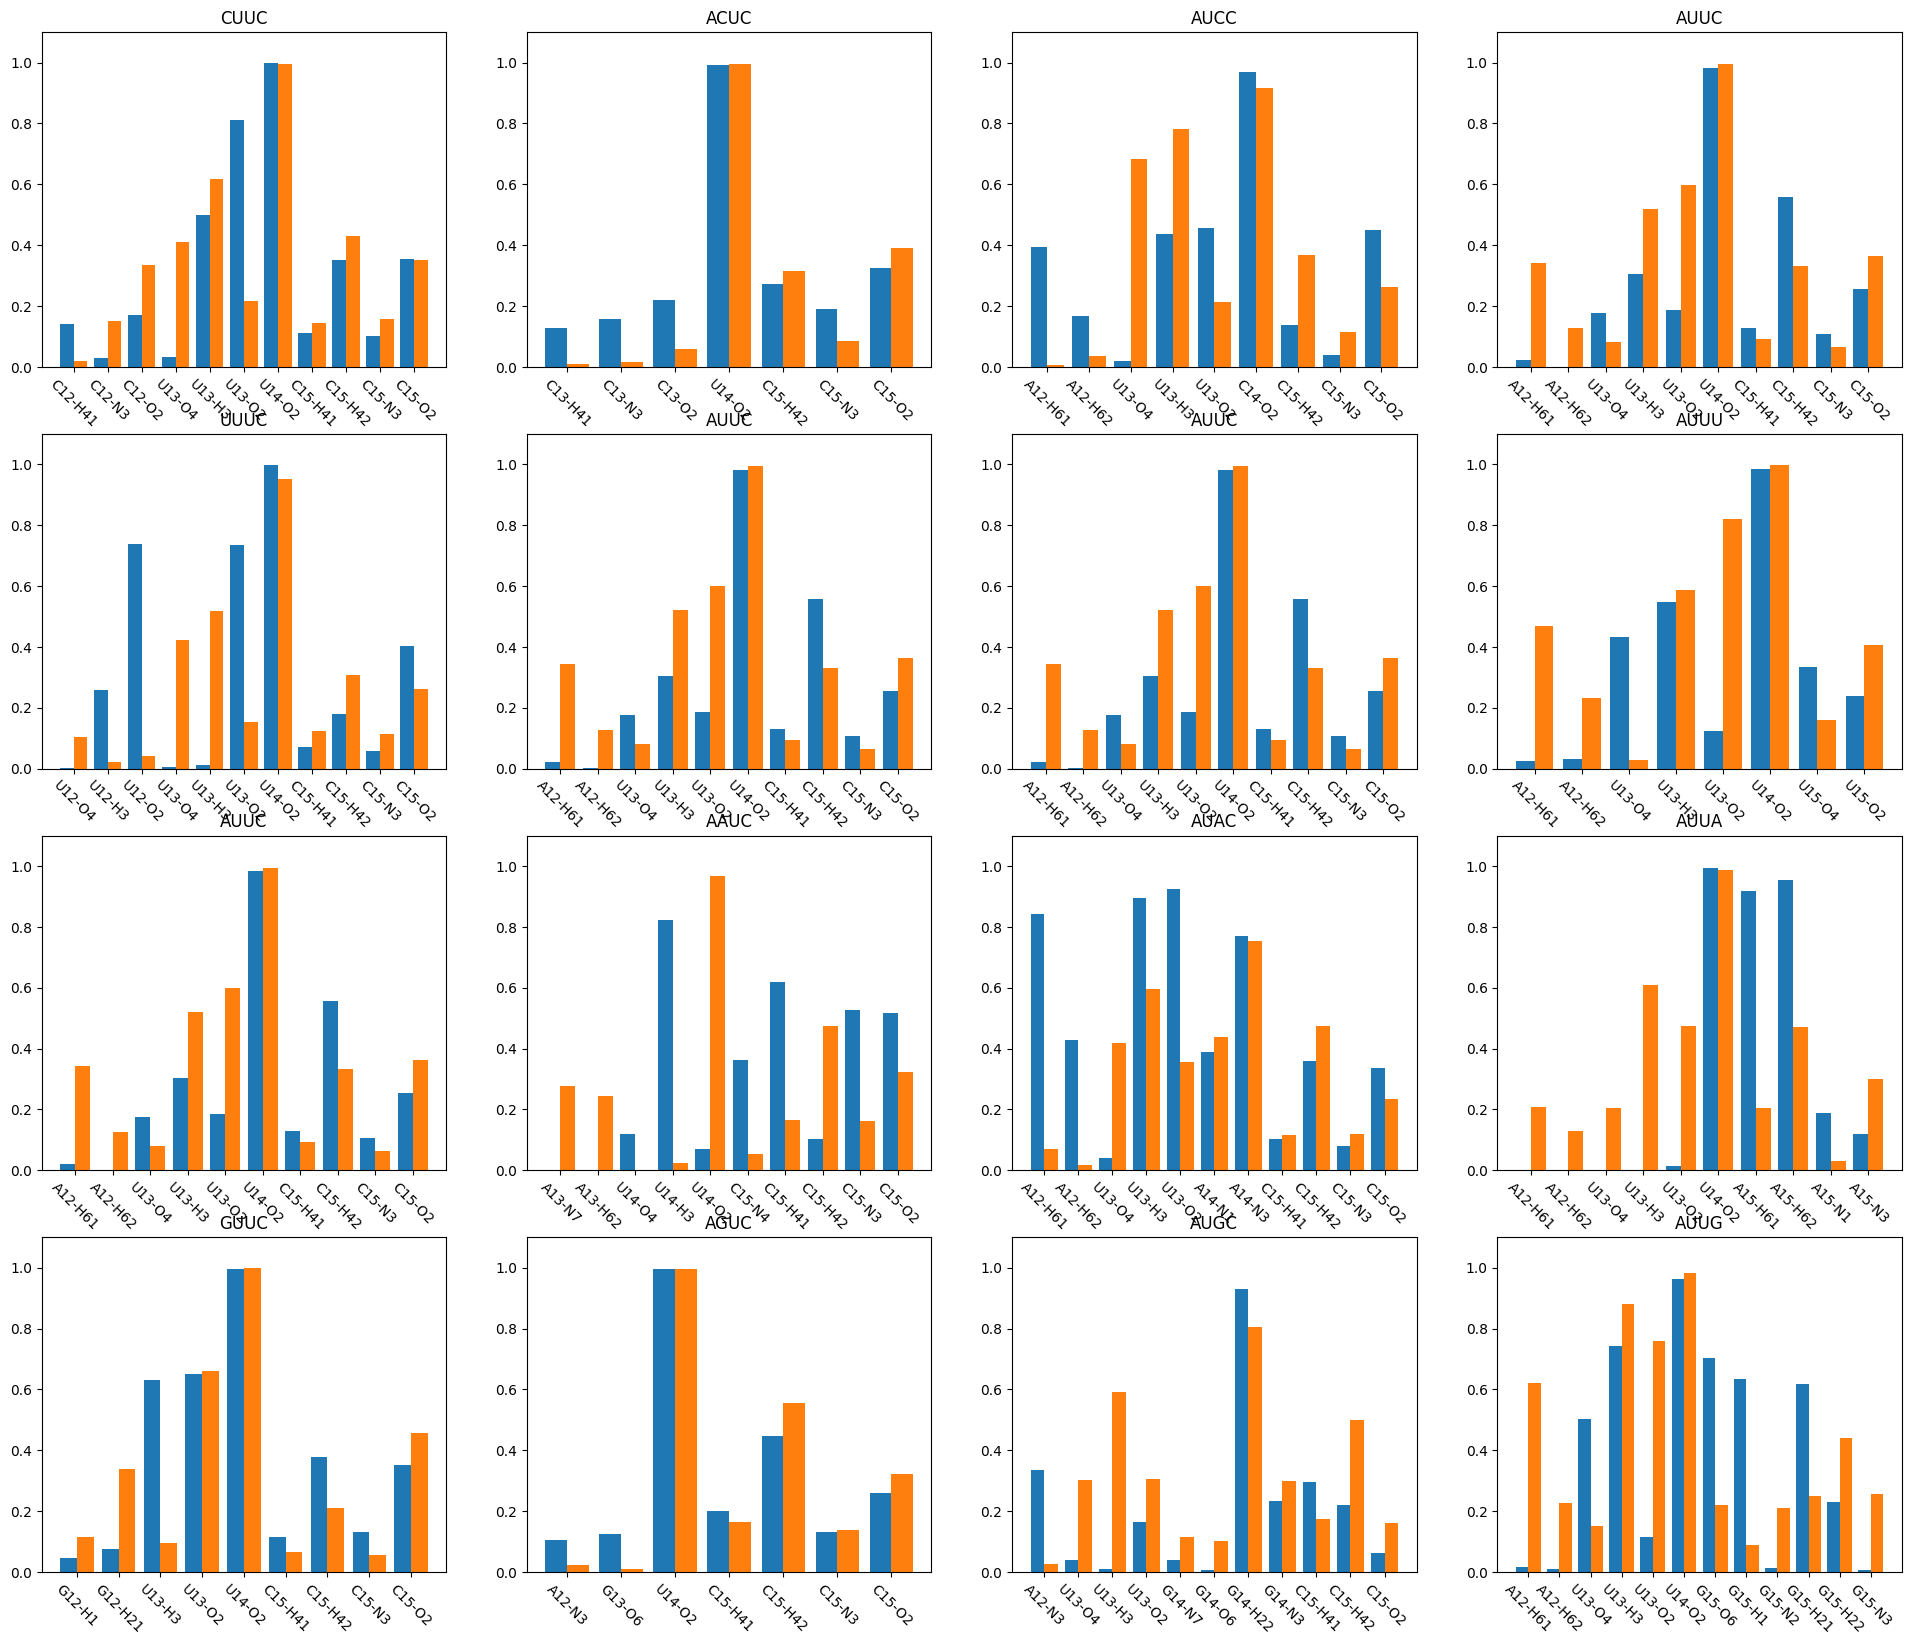

In [8]:
fig, ax = plt.subplots(4, 4)
fig.set_size_inches(24, 20)

for i_nucl, nucl in enumerate(nucls):
    print(nucl)
    metastabled_trajs_concat = pickle.load(open(f"./pickle-cache/pca_tetranucl_mut/metastabled_trajs_concat_{nucl}.pickle", "rb")).reshape(5, 15000)[:, ::10]
    fractions0 = interactions_mut[nucl].transpose(1, 2, 0, 3)[:, :, metastabled_trajs_concat==0].sum(axis=0).astype(bool).astype(np.int32).mean(axis=1)
    fractions1 = interactions_mut[nucl].transpose(1, 2, 0, 3)[:, :, metastabled_trajs_concat==1].sum(axis=0).astype(bool).astype(np.int32).mean(axis=1)

    dominant_pairs = []
    for residue_index_rna in range(11, 15):
        atom_indices_rna_residue = []
        for atom_index_rna_residue in gleap_targets[nucl].topology.select(f"resid {residue_index_rna}"):
            if "'" in gleap_targets[nucl].topology.atom(atom_index_rna_residue).name:
                continue
            if gleap_targets[nucl].topology.atom(atom_index_rna_residue).name in ["P", "OP1", "OP2"]:
                continue
            atom_indices_rna_residue.append(atom_index_rna_residue)
        
        for atom_index_rna in np.where((fractions0 > 0.1) | (fractions1 > 0.1))[0]:
            # dominant_pairs.append(atom_index_rna)
            if atom_index_rna in atom_indices_rna_residue:
                dominant_pairs.append(atom_index_rna)

    for ax_position in ax_positions[nucl]:
        xticks = []
        offset = 0
        for atom_index_rna in dominant_pairs:
            atom_rna     = gleap_targets[nucl].topology.atom(atom_index_rna)

            ax[ax_position].bar(offset-0.2, fractions0[atom_index_rna], width=0.4, color=colors[0]["rrm"])
            ax[ax_position].bar(offset+0.2, fractions1[atom_index_rna], width=0.4, color=colors[1]["rrm"])
            xticks.append(gleap_targets[nucl].topology.atom(atom_index_rna))
            print(gleap_targets[nucl].topology.atom(atom_index_rna), fractions0[atom_index_rna], fractions1[atom_index_rna])
            offset += 1
        ax[ax_position].set_title(nucl)
        ax[ax_position].set_ylim(0, 1.1)
        ax[ax_position].set_xticks(range(len(xticks)), xticks, rotation=-45)
        print()
    print("--------------------")
    print()

AUUC 11.822133333333333
A12-H61 0.1908
U13-O4 0.1252
U13-H3 0.418
U13-O2 0.4033333333333333
U14-O2 0.9885333333333334
C15-H41 0.11
C15-H42 0.4384
C15-O2 0.312

A12-H61 0.1908
U13-O4 0.1252
U13-H3 0.418
U13-O2 0.4033333333333333
U14-O2 0.9885333333333334
C15-H41 0.11
C15-H42 0.4384
C15-O2 0.312

A12-H61 0.1908
U13-O4 0.1252
U13-H3 0.418
U13-O2 0.4033333333333333
U14-O2 0.9885333333333334
C15-H41 0.11
C15-H42 0.4384
C15-O2 0.312

A12-H61 0.1908
U13-O4 0.1252
U13-H3 0.418
U13-O2 0.4033333333333333
U14-O2 0.9885333333333334
C15-H41 0.11
C15-H42 0.4384
C15-O2 0.312

--------------------

AAUC 11.395199999999999
A13-N7 0.24893333333333334
A13-H62 0.21813333333333335
U14-H3 0.10586666666666666
U14-O2 0.8752
C15-H41 0.21226666666666666
C15-H42 0.43693333333333334
C15-N3 0.1996
C15-O2 0.34213333333333334

--------------------

ACUC 11.840800000000002
C13-N3 0.106
C13-O2 0.16186666666666666
U14-O2 0.9922666666666666
C15-H42 0.28733333333333333
C15-N3 0.15186666666666668
C15-O2 0.3490666666666667

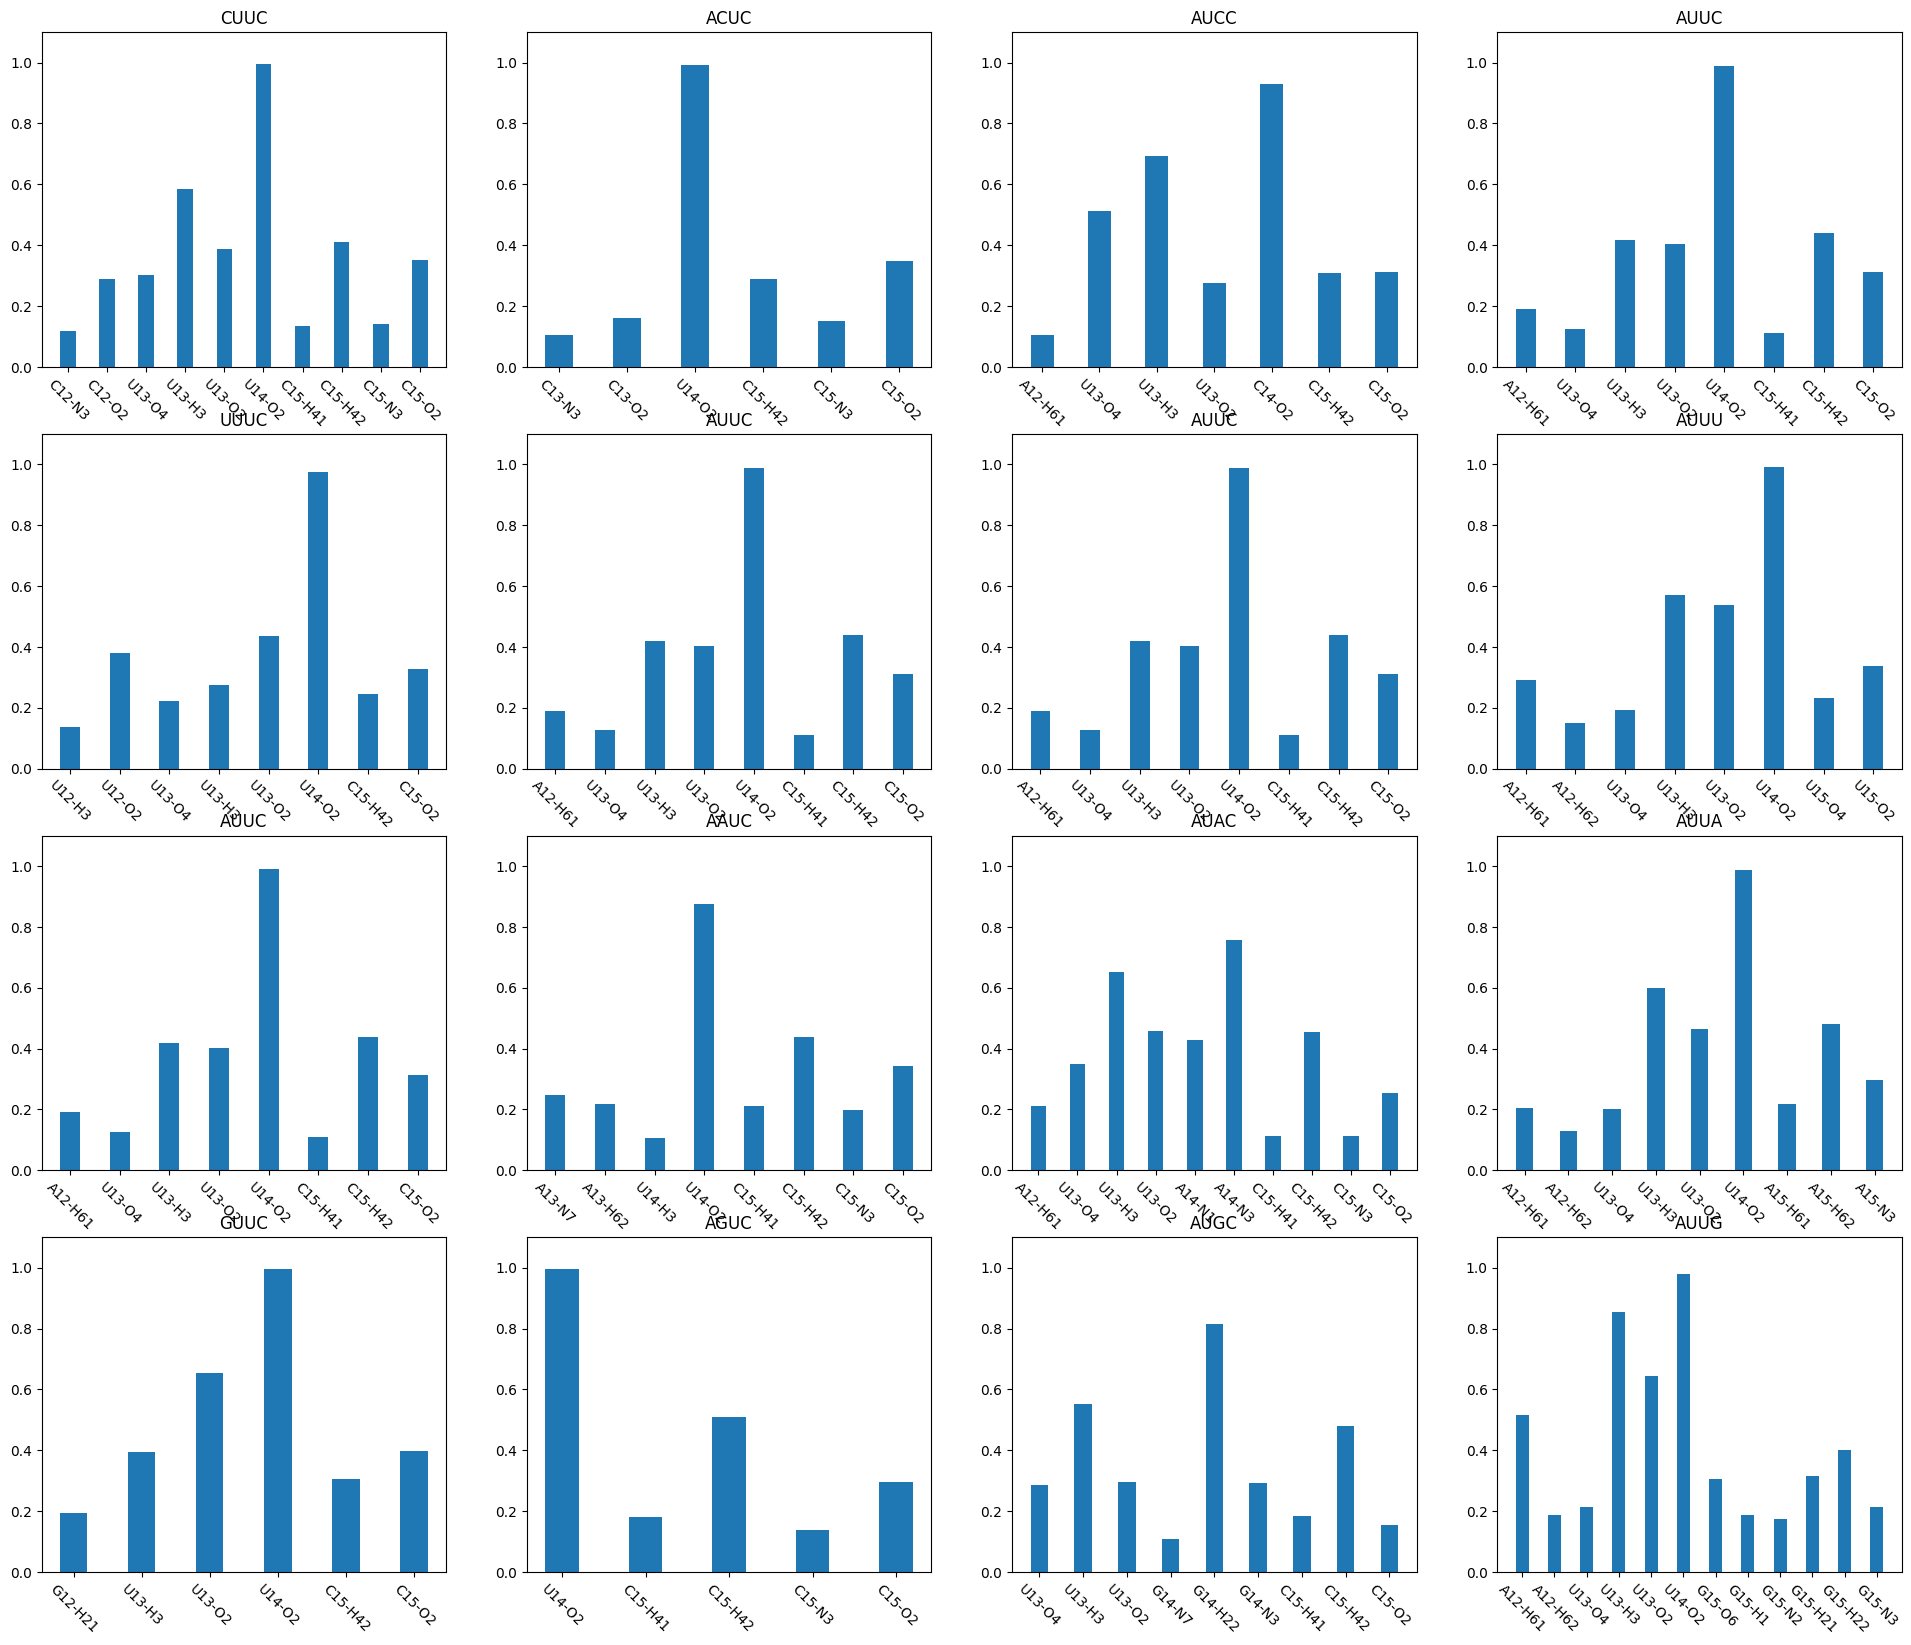

In [9]:
fig, ax = plt.subplots(4, 4)
fig.set_size_inches(24, 20)

for i_nucl, nucl in enumerate(nucls):
    fractions = interactions_mut[nucl].sum(axis=1).astype(bool).astype(np.int32).transpose(0, 2, 1).reshape(7500, -1).mean(axis=0)
    print(nucl, fractions.sum())

    dominant_pairs = []
    for residue_index_rna in range(11, 15):
        atom_indices_rna_residue = []
        for atom_index_rna_residue in gleap_targets[nucl].topology.select(f"resid {residue_index_rna}"):
            if "'" in gleap_targets[nucl].topology.atom(atom_index_rna_residue).name:
                continue
            if gleap_targets[nucl].topology.atom(atom_index_rna_residue).name in ["P", "OP1", "OP2"]:
                continue
            atom_indices_rna_residue.append(atom_index_rna_residue)
        
        for atom_index_rna in np.where(0.1 < fractions)[0]:
            # dominant_pairs.append(atom_index_rna)
            if atom_index_rna in atom_indices_rna_residue:
                dominant_pairs.append(atom_index_rna)

    for ax_position in ax_positions[nucl]:
        xticks = []
        offset = 0
        for atom_index_rna in dominant_pairs:
            atom_rna     = gleap_targets[nucl].topology.atom(atom_index_rna)

            ax[ax_position].bar(offset, fractions[atom_index_rna], width=0.4, color=colors[0]["rrm"])
            xticks.append(gleap_targets[nucl].topology.atom(atom_index_rna))
            print(gleap_targets[nucl].topology.atom(atom_index_rna), fractions[atom_index_rna])
            offset += 1
        ax[ax_position].set_title(nucl)
        ax[ax_position].set_ylim(0, 1.1)
        ax[ax_position].set_xticks(range(len(xticks)), xticks, rotation=-45)
        print()
    print("--------------------")
    print()